In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier

In [2]:
from sklearn.metrics import (
accuracy_score, precision_score, recall_score, f1_score,
confusion_matrix, classification_report, roc_auc_score, roc_curve
)

In [3]:
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.20, random_state=42, stratify=y
)

In [8]:
rf = RandomForestClassifier(random_state=42, n_jobs=-1)
param_grid = {
"n_estimators": [100],
"max_depth": [None, 10],
"min_samples_split" :[2],
"min_samples_leaf": [1]
}
grid = GridSearchCV(
estimator=rf,
param_grid=param_grid,
scoring="f1", cv=3, n_jobs=-1,
verbose=0)
grid.fit(X_train, y_train)

print("Best Parameters (CV)", grid.best_params_)
best_rf = grid.best_estimator_

Best Parameters (CV) {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}


In [9]:
best_rf.fit(X_train, y_train)
y_pred = best_rf.predict(X_test)
y_prob = best_rf.predict_proba(X_test)[:, 1]

In [10]:
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, zero_division=0)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)
cm = confusion_matrix(y_test, y_pred)
print("\n=== Random Forest — Test Metrics ===")
print(f"Accuracy : {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall : {rec:.4f}")
print(f"F1-Score : {f1:.4f}")
print(f"ROC-AUC : {auc:.4f}")
print("\nConfusion Matrix:\n", cm)
print("\nClassification Report:\n", classification_report(y_test, y_pred, zero_division=0))


=== Random Forest — Test Metrics ===
Accuracy : 0.9561
Precision: 0.9589
Recall : 0.9722
F1-Score : 0.9655
ROC-AUC : 0.9937

Confusion Matrix:
 [[39  3]
 [ 2 70]]

Classification Report:
               precision    recall  f1-score   support

           0       0.95      0.93      0.94        42
           1       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



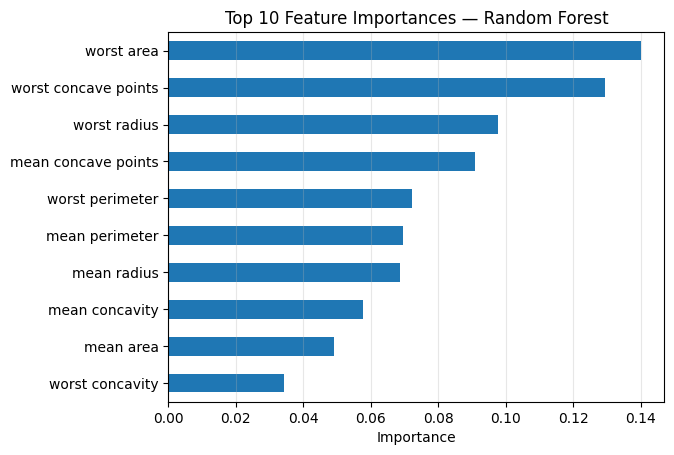

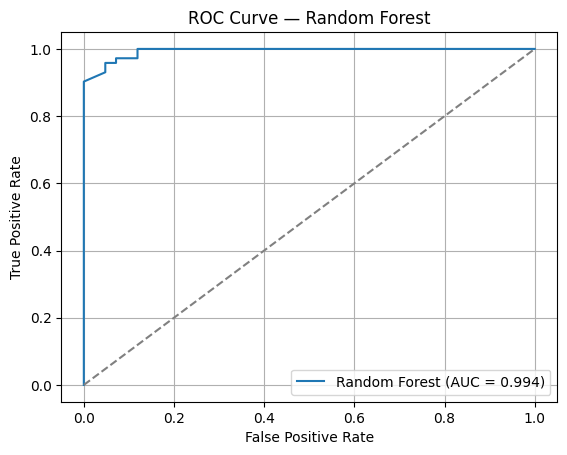

In [12]:
importances = pd.Series(best_rf.feature_importances_, index=X.columns)
top10 = importances.sort_values(ascending=False).head(10)
plt.figure()
top10[::-1].plot(kind="barh")
plt.xlabel("Importance")

plt.title("Top 10 Feature Importances — Random Forest")
plt.grid(axis="x", alpha=0.3)
plt.show()
# 9) ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
plt.figure()
plt.plot(fpr, tpr, label=f"Random Forest (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color='gray)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Random Forest")
plt.legend()
plt.grid(True)
plt.show()